# 01 — Exploring the Zhou et al. (2023) solubility database

**Task T3.** Goal: understand the raw ESI spreadsheet before writing `load_zhou.py` (T5) and `clean.py` (T7).

Source: Zhou et al., *Green Chem.* 2023, 25, 4402, DOI 10.1039/D3GC00404J, ESI file `d3gc00404j1_suppl.xlsx`.
All values are **COSMO-RS (COSMOtherm 19) predictions** in wt%, not measurements.

This notebook is exploration only: nothing in the pipeline imports from it.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
XLSX = ROOT / "data/raw/zhou2023/d3gc00404j1_suppl.xlsx"
XLSX.exists()

True

## 1. Which sheets are there?

In [2]:
xls = pd.ExcelFile(XLSX)
for name in xls.sheet_names:
    print(f"{name!r:32} shape={pd.read_excel(xls, name, header=None).shape}")

'All solubility predictions'     shape=(1009, 24)
'Solvent Info'                   shape=(1008, 9)


'30 common solvents'             shape=(32, 25)


- **All solubility predictions**: the main table. 1 row per solvent, wt% for 8 polymers × 2 temperatures, plus bp, Th and Hansen parameters.
- **Solvent Info**: SMILES and chemical class per solvent, with the same rows in the same order as the main sheet (checked in section 7).
- **30 common solvents**: a subset of familiar lab solvents with the same kind of predictions (checked in section 8).

## 2. Flatten the two-row header

Row 0 holds the group labels (`PS`, `Hansen solubility parameter`, ...), written once over merged cells.
Row 1 holds the sub-labels (`RT`/`Th`, `D`/`P`/`H`). Forward-fill row 0, then join it with row 1.

In [3]:
raw = pd.read_excel(xls, "All solubility predictions", header=None)
top = raw.iloc[0].ffill()
sub = raw.iloc[1]
flat = [t if pd.isna(s) else f"{t}_{s}" for t, s in zip(top, sub)]
flat

['Solvent name',
 'Solvent name in cosmobase',
 'CAS number',
 'Boiling point (°C)',
 'Th (°C)',
 'Hansen solubility parameter_D',
 'Hansen solubility parameter_P',
 'Hansen solubility parameter_H',
 'EVOH_RT',
 'EVOH_Th',
 'PE_RT',
 'PE_Th',
 'PET_RT',
 'PET_Th',
 'PP_RT',
 'PP_Th',
 'PS_RT',
 'PS_Th',
 'PVC_RT',
 'PVC_Th',
 'Nylon 6_RT',
 'Nylon 6_Th',
 'Nylon 66_RT',
 'Nylon 66_Th']

Rename to short, ASCII-safe names: the `°` in the header is mis-encoded, and `Nylon 6` contains a space.
Polymer short names used everywhere from now on: `EVOH, PE, PET, PP, PS, PVC, PA6, PA66`.

In [4]:
POLY_RENAME = {"Nylon 6": "PA6", "Nylon 66": "PA66"}
INFO_COLS = ["solvent_name", "cosmo_name", "cas", "bp_C", "Th_C", "dD", "dP", "dH"]

cols = INFO_COLS + [f"{POLY_RENAME.get(t, t)}_{s}" for t, s in zip(top[8:], sub[8:])]
df = raw.iloc[2:].reset_index(drop=True)
df.columns = cols
for c in ["bp_C", "Th_C", "dD", "dP", "dH"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

POLYMERS = ["EVOH", "PE", "PET", "PP", "PS", "PVC", "PA6", "PA66"]
VAL_COLS = [f"{p}_{t}" for p in POLYMERS for t in ("RT", "Th")]
print(df.shape)
df.head()

(1007, 24)


,solvent_name,cosmo_name,cas,bp_C,Th_C,dD,dP,dH,EVOH_RT,EVOH_Th,PE_RT,PE_Th,PET_RT,PET_Th,PP_RT,PP_Th,PS_RT,PS_Th,PVC_RT,PVC_Th,PA6_RT,PA6_Th,PA66_RT,PA66_Th
0,"1,1,1,2-Tetrachloroethane","1,1,1,2-tetrachloroethane",630-20-6,130.5,120.0,18.0,4.4,4.2,0.000015,0.865175,0.018997,22.9168,0.002114,1.43459,0.268136,19.965,0.448588,23.6196,0.469749,12.5395,0.023855,3.28543,0.00554,1.01569
1,"1,1,1-Trichloroethane","1,1,1-trichloroethane",71-55-6,74.0,73.0,16.8,4.3,2.0,0.000001,0.002199,0.035785,1.54522,0.000277,0.028064,0.689542,6.28198,0.815069,8.12062,0.484555,3.53827,0.000836,0.060568,0.000156,0.013716
2,"1,1,1-Trifluoroethane","1,1,1-trifluoroethane",420-46-2,-47.5,-48.5,14.6,10.0,0.0,NaN,0.0,NaN,0.000001,NaN,0.0,NaN,0.000239,NaN,0.000259,NaN,0.001257,NaN,0.0,NaN,0.0
3,"1,1,2,2-Tetrabromoethane","1,1,2,2-tetrabromoethane",79-27-6,243.5,120.0,21.0,7.0,8.2,0.000006,0.177392,0.000766,1.86759,0.054453,3.15973,0.002011,0.452499,0.111524,10.1647,0.032513,1.96492,0.007279,0.500425,0.001803,0.143467
4,"1,1,2,2-Tetrachloroethane","1,1,2,2-tetrachloroethane",79-34-5,146.5,120.0,18.8,5.1,5.3,0.00059,4.24464,0.013642,18.5723,0.12086,6.23066,0.158224,13.7393,0.719569,25.7243,0.748494,14.9923,2.71469,12.3777,1.02062,6.31144


In [5]:
print("duplicate solvent names:", df.solvent_name.duplicated().sum())
print("duplicate CAS:", df.cas.duplicated().sum(), "| missing CAS:", df.cas.isna().sum())
print("missing bp:", df.bp_C.isna().sum(), "| missing Th:", df.Th_C.isna().sum())
print("missing Hansen dD:", df.dD.isna().sum())

bp_ok = df.bp_C.notna()
rule = np.minimum(df.bp_C - 1, 120)
print("Th == min(bp-1, 120) where bp known:", np.isclose(df.Th_C[bp_ok], rule[bp_ok]).sum(), "/", bp_ok.sum())
print("Th values where bp is missing:", df.Th_C[~bp_ok].value_counts().to_dict())
same = np.isclose(pd.to_numeric(df.PS_RT, errors="coerce"), pd.to_numeric(df.PS_Th, errors="coerce"))
print("solvents with PS_RT == PS_Th exactly:", same.sum(), "| of these, bp missing:", (same & ~bp_ok).sum())

duplicate solvent names: 0
duplicate CAS: 18 | missing CAS: 2
missing bp: 162 | missing Th: 0
missing Hansen dD: 29
Th == min(bp-1, 120) where bp known: 845 / 845
Th values where bp is missing: {25.0: 162}
solvents with PS_RT == PS_Th exactly: 162 | of these, bp missing: 158


**Findings.**
- 1007 solvents × 24 columns, which matches the paper.
- `solvent_name` is unique, but **CAS is not** (18 duplicates, 2 missing). CAS is therefore not a safe join key (see section 7).
- Where bp is known (845 solvents), Th = min(bp − 1, 120) always holds.
- ⚠️ **162 solvents have no bp, and for all of them Th = 25 °C**. Their "Th" column is just a copy of the RT values (identical numbers).
  So these solvents have **only one real temperature**. Among them is GVL, which really boils at about 207 °C.
  **Suggestion for T7:** drop the Th rows of these solvents, so they don't appear twice at the same T.
  As a consequence, the "GVL at high T" sanity check in T28 cannot be checked against Zhou.
- 29 solvents have no Hansen parameters. That matters for Ra² and B_HSP (T14), because those rows have no physics prior.

## 3. Value types per polymer: `M`, `NaN`, tiny numbers

In [6]:
rows = []
for c in VAL_COLS:
    v = df[c]
    num = pd.to_numeric(v, errors="coerce")
    rows.append({
        "column": c,
        "M (miscible)": int((v == "M").sum()),
        "NaN": int(v.isna().sum()),
        "numeric": int(num.notna().sum()),
        "< 1e-3 wt%": int((num < 1e-3).sum()),
        "min": num.min(),
        "max": num.max(),
    })
counts = pd.DataFrame(rows).set_index("column")
counts

,M (miscible),NaN,numeric,< 1e-3 wt%,min,max
column,,,,,,
EVOH_RT,0,81,926,624,1.446220e-10,20.44730
EVOH_Th,1,14,992,226,2.626630e-26,35.33030
PE_RT,0,73,934,85,7.045600e-08,5.80188
PE_Th,0,2,1005,78,2.984590e-19,41.78120
PET_RT,0,78,929,465,8.439900e-19,10.11290
PET_Th,0,8,999,164,1.795590e-17,19.84620
PP_RT,0,76,931,69,8.377560e-11,5.35735
PP_Th,0,5,1002,50,1.333910e-12,44.70450
PS_RT,0,77,930,77,7.930710e-18,23.04410


**Findings.**
- **`M` appears only twice in the whole file**: PS_Th in ethylene dinitrate, and EVOH_Th in ethylenediamine. So censoring (as in CLAUDE.md) affects 2 labels.
  It is still worth implementing, but it barely matters for training.
- There are **no exact zeros**, and the column holds nothing other than numbers, `M` and NaN. But the values go down to about 1e-23 wt%.
  `log10(wt% + 1e-3)` floors everything below about 1e-3. That is intended (those are all "insoluble"), but there are many such rows,
  e.g. 465 of 1007 for PET at RT. Expect a big spike at −3 in the target distribution.
- PA6 and PA66 have more NaNs than the other polymers (113–119 at RT, against about 75), so NaN does **not only** mean "boils below RT". See section 4.

## 4. Temperatures and the meaning of `NaN`

In [7]:
low_bp = df.bp_C < 25
print("solvents with bp < 25 °C:", low_bp.sum())
print("solvents with Th < 25 °C:", (df.Th_C < 25).sum())
pd.crosstab(low_bp.rename("bp < 25 °C"), df.PS_RT.isna().rename("PS_RT is NaN"))

solvents with bp < 25 °C: 71
solvents with Th < 25 °C: 71


PS_RT is NaN,False,True
bp < 25 °C,,
False,930,6
True,0,71


In [8]:
# NaN at RT although the solvent does not boil below RT
odd = df[~low_bp & df.PS_RT.isna()]
odd[["solvent_name", "bp_C", "Th_C", "PS_RT", "PS_Th"]]

,solvent_name,bp_C,Th_C,PS_RT,PS_Th
758,Nitric Acid,NaN,25.0,NaN,NaN
762,Nitroglycerin (Glyceryl Trinitrate),250.0,120.0,NaN,NaN
786,Ozone,NaN,25.0,NaN,NaN
861,"Pyrogallol (1,2,3-Trihydroxybenzene)",309.0,120.0,NaN,NaN
896,Tetranitromethane,NaN,25.0,NaN,NaN
936,Trinitromethane,NaN,25.0,NaN,NaN


In [9]:
# Below-ambient Th: these solvents still have Th predictions
df.loc[df.Th_C < 25, ["solvent_name", "bp_C", "Th_C", "PS_RT", "PS_Th", "PET_Th"]].head(8)

,solvent_name,bp_C,Th_C,PS_RT,PS_Th,PET_Th
2,"1,1,1-Trifluoroethane",-47.5,-48.5,NaN,0.000259,0.0
16,"1,1-Difluoroethane",-24.9,-25.9,NaN,0.012582,0.000009
17,"1,1-Difluoroethylene",-85.7,-86.7,NaN,0.000077,0.0
28,"1,2-Butadiene",10.9,9.9,NaN,6.04891,0.001804
34,"1,2-Dichlorotetrafluoroethane (Freon 114)",3.8,2.8,NaN,0.000548,0.0
41,"1,2-Propadiene (Allene)",-34.4,-35.4,NaN,0.86739,0.000072
45,"1,3-Butadiene",-4.4,-5.4,NaN,2.74393,0.000534
69,1-Butene,-6.2,-7.2,NaN,0.998015,0.000016


In [10]:
# Extra NaNs for the nylons: which solvents?
extra = df[df.PA6_Th.isna() & df.PS_Th.notna()]
print(len(extra), "solvents have PS_Th but no PA6_Th")
extra[["solvent_name", "bp_C", "Th_C"]].head(10)

26 solvents have PS_Th but no PA6_Th


,solvent_name,bp_C,Th_C
36,"1,2-Dihydroxybenzene (Catechol)",245.0,120.0
43,"1,3-Benzenediol",280.0,120.0
57,"1,4-Dihydroxybenzene (1,4-Benzenediol)",287.0,120.0
93,1-Naphthol,288.0,120.0
181,2-t-Butyl-4-Methyl Phenol,237.0,120.0
188,"3,4-Dimethyl Phenol",227.0,120.0
189,"3,4-Dinitrophenol",NaN,25.0
191,"3,5-Dinitrophenol",NaN,25.0
221,4-Ethyl Phenol,217.9,120.0
227,4-Nitrophenol,279.0,120.0


**Findings.**
- All 71 solvents with bp < 25 °C have NaN at RT, which confirms "NaN = boils below RT". But **their Th column is filled**, with Th = bp − 1 < 25 °C (as low as −48.5 °C).
  These are COSMO-RS predictions at a *sub-ambient* temperature. **Suggestion for T7:** keep them as training rows, since T in K works fine in χ = A + B/T.
  They can never pass screening anyway, because the T grid starts at 25 °C.
- 6 solvents are NaN at both temperatures for other reasons (nitric acid, ozone, nitroglycerin, ...), most likely COSMO-RS failures. Drop them.
- The extra PA6/PA66 NaNs are mostly phenols and diols with high bp, so they are not a boiling-point issue (probably no converged COSMO-RS result).
  Consequence: **"drop NaN" must be done per (solvent, polymer, T) row in the long table**, not per solvent.

## 5. Wide → long (prototype for T5)

In [11]:
long = df.melt(id_vars=INFO_COLS, value_vars=VAL_COLS, var_name="col", value_name="raw_value")
long[["polymer", "T_label"]] = long.col.str.split("_", expand=True)
long = long.drop(columns="col")
long["is_miscible"] = long.raw_value.eq("M")
long["wt_pct"] = pd.to_numeric(long.raw_value, errors="coerce")
long["T_K"] = np.where(long.T_label == "RT", 298.15, long.Th_C + 273.15)

print("long rows (all):", len(long))
print("rows with a usable label (numeric or M):", (long.wt_pct.notna() | long.is_miscible).sum())
long.head()

long rows (all): 16112
rows with a usable label (numeric or M): 15322


,solvent_name,cosmo_name,cas,bp_C,Th_C,dD,dP,dH,raw_value,polymer,T_label,is_miscible,wt_pct,T_K
0,"1,1,1,2-Tetrachloroethane","1,1,1,2-tetrachloroethane",630-20-6,130.5,120.0,18.0,4.4,4.2,0.000015,EVOH,RT,False,0.000015,298.15
1,"1,1,1-Trichloroethane","1,1,1-trichloroethane",71-55-6,74.0,73.0,16.8,4.3,2.0,0.000001,EVOH,RT,False,0.000001,298.15
2,"1,1,1-Trifluoroethane","1,1,1-trifluoroethane",420-46-2,-47.5,-48.5,14.6,10.0,0.0,NaN,EVOH,RT,False,NaN,298.15
3,"1,1,2,2-Tetrabromoethane","1,1,2,2-tetrabromoethane",79-27-6,243.5,120.0,21.0,7.0,8.2,0.000006,EVOH,RT,False,0.000006,298.15
4,"1,1,2,2-Tetrachloroethane","1,1,2,2-tetrachloroethane",79-34-5,146.5,120.0,18.8,5.1,5.3,0.00059,EVOH,RT,False,0.000590,298.15


1007 × 8 × 2 = 16 112 rows before cleaning. **RT is taken as 298.15 K.** The paper does not state an exact value, so record this as an assumption.

## 6. PS and PET solubility distributions

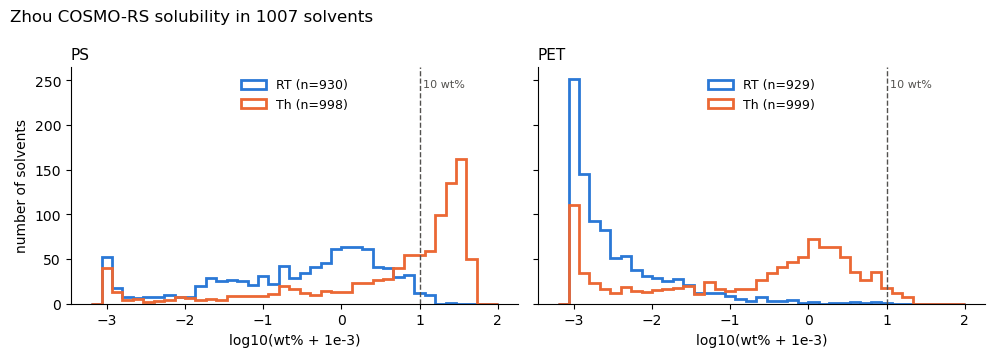

In [12]:
FLOOR = 1e-3
C_RT, C_TH = "#2a78d6", "#eb6834"   # blue = RT, orange = Th
INK = "#52514e"
bins = np.linspace(-3.2, 2.0, 40)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, poly in zip(axes, ["PS", "PET"]):
    for t, color in (("RT", C_RT), ("Th", C_TH)):
        y = np.log10(pd.to_numeric(df[f"{poly}_{t}"], errors="coerce").dropna() + FLOOR)
        ax.hist(y, bins=bins, histtype="step", lw=2, color=color, label=f"{t} (n={len(y)})")
    ax.axvline(1.0, color=INK, lw=1, ls="--")
    ax.text(1.05, 0.95, "10 wt%", color=INK, fontsize=8, transform=ax.get_xaxis_transform(), va="top")
    ax.set_title(poly, loc="left", fontsize=11)
    ax.set_xlabel("log10(wt% + 1e-3)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper center")
axes[0].set_ylabel("number of solvents")
fig.suptitle("Zhou COSMO-RS solubility in 1007 solvents", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

In [13]:
desc = {f"{p}_{t}": pd.to_numeric(df[f"{p}_{t}"], errors="coerce").describe(percentiles=[.5, .9, .95])
        for p in ("PS", "PET") for t in ("RT", "Th")}
pd.DataFrame(desc).round(3)

,PS_RT,PS_Th,PET_RT,PET_Th
count,930.000,998.000,929.000,999.000
mean,1.501,15.312,0.061,1.639
std,2.485,13.934,0.528,2.918
min,0.000,0.000,0.000,0.000
50%,0.524,12.105,0.001,0.500
90%,4.371,35.378,0.028,4.606
95%,6.527,39.710,0.080,7.829
max,23.044,52.407,10.113,19.846


**Findings.**
- At RT, PS and PET are poorly soluble almost everywhere. Heating to Th moves the whole distribution up by about 1–2 decades.
- At Th, PS has a large group of good solvents (above 10 wt%).
- PET sits much lower, with a big pile at the 1e-3 floor. Its upper tail at Th still reaches about 20 wt%, so some solvents dissolve both polymers.

## 7. Solvent Info, SMILES parse rate, duplicates

In [14]:
info = pd.read_excel(xls, "Solvent Info")
info = info.rename(columns={"Solvent name": "solvent_name", "SMILES": "smiles",
                            "Classes": "class1", "Unnamed: 5": "class2"})
print(info.columns.tolist())
print("same order as main sheet:", (info.solvent_name.values == df.solvent_name.values).all())
print("rows with a 2nd class:", info.class2.notna().sum(), "| missing class:", info.class1.isna().sum())
print("non-empty values in Unnamed: 6/7/8:", info[["Unnamed: 6", "Unnamed: 7", "Unnamed: 8"]].notna().sum().to_dict())

['solvent_name', 'Solvent name in cosmobase', 'CAS number', 'smiles', 'class1', 'class2', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']
same order as main sheet: True
rows with a 2nd class: 371 | missing class: 25
non-empty values in Unnamed: 6/7/8: {'Unnamed: 6': 40, 'Unnamed: 7': 2, 'Unnamed: 8': 1}


The unnamed columns are **not** misaligned data. They hold extra class labels: a molecule can have up to 5 (e.g. 1,2-dimethoxybenzene = Ether + Aromatics; quinine has 5).
Only `class1` and `class2` are kept here. Classes are only used for analysis, never as model input.
Join `Solvent Info` to the main sheet **on `solvent_name`**, which is unique. Do not join on CAS, because the 18 duplicate CAS would multiply rows.

In [15]:
mols = info.smiles.astype(str).map(Chem.MolFromSmiles)
print(f"SMILES parsed: {mols.notna().sum()} / {len(mols)}  ({mols.notna().mean():.1%})")
info["can_smiles"] = [Chem.MolToSmiles(m) for m in mols]
print("unique canonical SMILES:", info.can_smiles.nunique())
print("SMILES with stereo marks (@, /, \\):", info.can_smiles.str.contains(r"[@/\\]").sum())

SMILES parsed: 1007 / 1007  (100.0%)


unique canonical SMILES: 983
SMILES with stereo marks (@, /, \): 0


In [16]:
df = df.merge(info[["solvent_name", "smiles", "can_smiles", "class1", "class2"]], on="solvent_name", how="left")
dups = df[df.can_smiles.duplicated(keep=False)].sort_values("can_smiles")
dups[["solvent_name", "cosmo_name", "can_smiles", "dD", "dP", "dH", "PS_Th", "PET_Th"]]

,solvent_name,cosmo_name,can_smiles,dD,dP,dH,PS_Th,PET_Th
31,"1,2-Dibromoethylene",cis-dibromoethene,BrC=CBr,17.0,4.9,3.0,20.9708,4.20472
973,"1,2-dibromoethylene",trans-dibromoethene,BrC=CBr,18.0,4.9,3.0,19.3589,2.87113
482,Diphenyl Acetylene (0 Dipole Moment),"1,1'-(1,2-ethynediyl)bisbenzene",C(#Cc1ccccc1)c1ccccc1,18.0,2.0,3.2,22.8019,1.53386
483,Diphenyl Acetylene (P By Group Cont.),"1,1'-(1,2-ethynediyl)bisbenzene",C(#Cc1ccccc1)c1ccccc1,18.0,2.0,3.2,22.8019,1.53386
913,Trans-Decahydronaphthalene,trans-decalin,C1CCC2CCCCC2C1,18.0,0.0,0.0,7.52404,0.01606
360,Cis-Decahydronaphthalene,cis-decalin,C1CCC2CCCCC2C1,17.6,0.0,0.0,8.49493,0.018692
59,"1,4-Dioxane (High P)",dioxane,C1COCCO1,17.1,6.8,7.8,29.9923,2.22713
58,"1,4-Dioxane",dioxane,C1COCCO1,17.5,1.8,9.0,29.9923,2.22713
320,Butadienedioxide,"1,3-butadienediepoxide",C1OC1C1CO1,18.3,14.4,6.2,20.965,2.26112
976,butadienedioxide,"1,2-3,4-diepoxybutane",C1OC1C1CO1,18.3,14.4,6.2,14.8789,1.82025


**Findings: important for T7 (dedupe) and T9 (splits).**
- **100 % of SMILES parse.** There are no `*` atoms or salts.
- The 1007 rows contain **983 unique molecules**: 22 molecules appear 2–3 times. There are two kinds of duplicate:
  1. **The same COSMO compound under different Hansen-handbook entries** (e.g. "Carbon Tetrachloride (0 Dipole Moment)" and "(P By Group Cont.)", or Methanol and Methanol Cluster).
     `cosmo_name` is identical, so the **labels are identical** and only the HSP differ. Keep one row per `cosmo_name`, and choose which HSP set to keep (e.g. the plain entry).
  2. **Stereoisomers that collapse because the SMILES carry no stereo**: cis/trans-2-butene, cis/trans-decalin, cis/trans-crotonaldehyde, ...
     Here `cosmo_name` differs, and **so do the labels, sometimes a lot** (crotonaldehyde PS_Th: 38.2 vs 3.4 wt%).
     The GNN would see identical graphs with conflicting targets. Options: add stereo to the SMILES by hand, keep one isomer, or average.
     Whatever you choose, **all rows of one molecule must be in the same split**. Otherwise the same molecule leaks between train and test.
- Use the canonical SMILES (not the name) as the molecule identity for graphs, caching and the scaffold split.

In [17]:
df.class1.value_counts().head(12)

class1
Ester              126
Alcohol            107
Aromatics           98
Ether               85
Alkene              82
AlkylHalide         77
Ketone              54
Amine               49
Nitrogen            42
Nitrile             41
Alkane              37
Carboxylic Acid     34
Name: count, dtype: int64

## 8. The "30 common solvents" sheet

In [18]:
c30 = pd.read_excel(xls, "30 common solvents", header=None)
c30v = c30.iloc[2:, [2, 17]].set_axis(["cosmo_name", "PS_RT_c30"], axis=1)   # cosmobase name, PS RT
c30v["cosmo_name"] = c30v.cosmo_name.str.lower()
m = df.assign(cosmo_name=df.cosmo_name.str.lower()).merge(c30v, on="cosmo_name")
same = np.isclose(pd.to_numeric(m.PS_RT, errors="coerce"), pd.to_numeric(m.PS_RT_c30, errors="coerce"), equal_nan=True)
print("rows in sheet:", len(c30v), "| matched by cosmo_name:", m.cosmo_name.nunique(), "| PS_RT identical:", same.sum(), "/", len(m))

rows in sheet: 30 | matched by cosmo_name: 30 | PS_RT identical: 33 / 33


This sheet repeats the predictions for familiar lab solvents (with lab names and abbreviations). It contains **no experimental data**, so it is not a test set.

## 9. Experimental data in the paper (for the external test set)

From the paper text, not the spreadsheet:
- **Table 1, "reference experimental input"**: one measured solubility per polymer (e.g. PS in toluene, 110 °C, 41.2 wt%; PET in DMSO, 135 °C, 13.3 wt%).
  ⚠️ These measurements were used to **calibrate** the COSMO-RS calculations, so they are *not independent* of the training labels.
  Do not count them as external test points, or report them separately.
- **Table 3, "experimental verification"**: 1 good solvent + 1 non-solvent per polymer, with 14 usable measured values. These are the real external experimental points.
  For our pair: PS/THF, PS/2-propanol, PET/DMF (the known miss: predicted good, but a non-solvent in experiment) and PET/acetone.
  ⚠️ The table layout gets garbled when the PDF is converted to text. **Read Table 3 directly in the PDF before you copy numbers into `exp_test.csv`.**
- The ESI PDF also describes separation case studies (PE/PS, PVC/PET, EVOH/PP/PET), which are useful qualitative checks for screening (T28).

## 10. PS-selective solvents
Criterion (screening thresholds from CLAUDE.md): **PS ≥ 10 wt% and PET ≤ 0.5 wt%** at the same temperature. `M` counts as ≥ 10 for PS and as a fail for PET.
At Th we also require Th ≥ 25 °C, because a sub-ambient Th is not a process condition.

In [19]:
def num(c):
    return pd.to_numeric(df[c], errors="coerce")

def selective(t):
    ps_ok = (num(f"PS_{t}") >= 10) | (df[f"PS_{t}"] == "M")
    pet_ok = num(f"PET_{t}") <= 0.5           # 'M' -> NaN -> False
    return ps_ok & pet_ok

sel_th = selective("Th") & (df.Th_C >= 25)
sel_rt = selective("RT")
print("PS-selective at RT:", sel_rt.sum())
print("PS-selective at Th (Th >= 25 °C):", sel_th.sum(), "| without the Th filter:", selective("Th").sum())
print("unique molecules among Th-selective:", df.loc[sel_th, "can_smiles"].nunique())

PS-selective at RT: 14
PS-selective at Th (Th >= 25 °C): 104 | without the Th filter: 106
unique molecules among Th-selective: 102


In [20]:
top15 = df.loc[sel_th, ["solvent_name", "class1", "Th_C", "PS_Th", "PET_Th"]].copy()
top15["PS_Th"] = pd.to_numeric(top15.PS_Th, errors="coerce")
top15.sort_values("PS_Th", ascending=False).head(15)

,solvent_name,class1,Th_C,PS_Th,PET_Th
78,1-Chlorohexane,AlkylHalide,120.00,30.6297,0.492413
703,Methyl Nitrate,Nitrogen,64.00,30.1804,0.385149
70,1-Chloro Pentane,AlkylHalide,106.80,28.7652,0.39265
357,Chloropicrin (Trichloronitromethane),Nitrogen,111.00,28.4901,0.149861
161,2-Methyl Tetrahydrofuran,Ether,77.00,28.1476,0.391443
15,"1,1-Diethoxy Ethane",Ether,101.20,27.2562,0.400119
883,t-Butyl Acetate,Ester,96.00,26.6161,0.460295
327,Butyleneoxide,Ether,62.30,26.1491,0.346436
405,Di-n-Butyl Ether,Ether,120.00,25.8505,0.254371
481,Dipentene (Dl-Limonene),Alkene,120.00,25.4263,0.287731


In [21]:
df.loc[sel_th, "class1"].value_counts()

class1
Ether          22
Alkene         19
Alcohol        15
AlkylHalide     9
Ester           9
Amine           5
Aromatics       4
Nitrogen        4
Sulfide         3
Acylhalide      3
Aldehyde        2
Alkane          2
Ketone          1
Alkyne          1
Silicon         1
Name: count, dtype: int64

In [22]:
# Sanity check on solvents named in the build plan
pat = "limonene|cymene|valerolactone|dimethylformamide|^toluene$|^tetrahydrofuran$"
df[df.solvent_name.str.contains(pat, case=False, regex=True)][["solvent_name", "cas", "Th_C", "PS_RT", "PS_Th", "PET_RT", "PET_Th"]]

,solvent_name,cas,Th_C,PS_RT,PS_Th,PET_RT,PET_Th
481,Dipentene (Dl-Limonene),138-86-3,120.0,0.567115,25.4263,0.000065,0.287731
911,Toluene,108-88-3,109.6,3.64244,40.9649,0.002997,2.53994


In [23]:
# Same check by CAS (names in the database are not standardised)
cas = {"p-cymene": "99-87-6", "GVL": "108-29-2", "DMF": "68-12-2", "toluene": "108-88-3", "THF": "109-99-9", "d-limonene": "5989-27-5"}
df[df.cas.isin(cas.values())][["solvent_name", "cas", "Th_C", "PS_RT", "PS_Th", "PET_RT", "PET_Th"]]

,solvent_name,cas,Th_C,PS_RT,PS_Th,PET_RT,PET_Th
470,Dimethyl Formamide (DMF),68-12-2,120.0,7.37741,47.8679,0.154304,18.3548
888,Tetrahydrofuran (THF),109-99-9,64.0,13.9636,31.2636,0.037939,0.810312
911,Toluene,108-88-3,109.6,3.64244,40.9649,0.002997,2.53994
993,GVL,108-29-2,25.0,0.793144,0.793144,0.003967,0.003967


**Findings.**
- Only 14 solvents are PS-selective at RT. At Th about 100 are, which is the main point: **selective PS dissolution needs heat**.
- The selective set is dominated by ethers, alkenes (terpenes such as dipentene/limonene), alcohols, esters and haloalkanes.
  Several are clearly not green (chloroalkanes, methyl nitrate, chloropicrin), so the greenness filter (T11) will matter.
- Limonene ("Dipentene (Dl-Limonene)") is selective at 120 °C: PS 25.4 and PET 0.29 wt%. That agrees with the essential-oil PS recycling literature (Polystyvert).
- Sanity solvents from the build plan:
  - **p-cymene and d-limonene (CAS 5989-27-5) are not in the database.** Limonene exists only as racemic dipentene (CAS 138-86-3).
  - **GVL** is present, but only at 25 °C (bp missing, see section 2), so "GVL rejected at high T" cannot be checked from Zhou.
  - **DMF** at 120 °C dissolves both polymers (PS 47.9, PET 18.4 wt%), so it is correctly not selective. Remember that experimentally DMF does *not* dissolve PET (Table 3).
  - **THF** is not selective at Th (PET 0.81 wt% > 0.5).

## 11. Summary (T3 "done when")

**The file in 3 sentences.** The Zhou ESI is one wide sheet of COSMO-RS-predicted solubilities (wt%) for 8 polymers in 1007 solvents, at RT and at Th = min(bp − 1, 120) °C.
A second sheet gives SMILES and classes in the same row order, and a third repeats 30 common solvents.
Labels are numeric down to about 1e-23 wt%. `M` (miscible) occurs only twice, and NaN marks the 71 solvents that boil below RT (RT column only) plus some COSMO-RS gaps (mostly nylons).
162 solvents have no bp, and their "Th" is simply 25 °C, a copy of RT. All 1007 SMILES parse, but they describe only 983 unique molecules.

**Key numbers** (copy into the progress log):

| | |
|---|---|
| solvents / unique molecules | 1007 / 983 |
| long rows before cleaning | 16 112 |
| `M` labels | 2 |
| SMILES parse rate | 100 % |
| PS-selective (PS ≥ 10, PET ≤ 0.5 wt%) at RT | 14 |
| PS-selective at Th (Th ≥ 25 °C) | 104 |

**Open issues for T5 / T7 / T9.**
1. Join the sheets on `solvent_name`, not CAS.
2. Dedupe: rows with the same `cosmo_name` have identical labels, so keep one. Stereoisomer pairs need a decision. Group by canonical SMILES in the split.
3. Keep sub-ambient Th rows for training. Drop NaN per row, not per solvent. Drop the duplicated Th rows of the 162 solvents with no bp (Th = 25 °C).
4. 29 solvents lack HSP, so they have no physics prior. Decide whether to drop them or use `mask = 0` for them.
5. RT = 298.15 K (an assumption; state it in the report).
6. External test set: use Table 3 only. The Table 1 values were used for calibration.